# Federated learning for cassava disease diagnosis across farms

This notebook trains a cassava leaf-disease classifier across simulated farms without
pooling their images, then checks how far the result can be trusted: how much accuracy
federation costs, how the worst-served farm does, whether the model's confidence is
calibrated, whether it is less certain on the cases it gets wrong, what client-level
differential privacy costs, and whether a model small enough for a phone holds up.

The data are the iCassava 2019 images: 5,656 labelled leaf photographs in five classes
(cassava bacterial blight, brown streak disease, green mottle, mosaic disease and healthy)
and about 16,000 unlabelled ones. The farms are simulated by splitting this one dataset,
with a Dirichlet prior on each farm's mix of diseases, so the study tests the training
methods rather than a real deployment. The images are RGB only.

To run it, use a GPU runtime (an L4 is enough), put the archive in Drive at the path in §2
and choose Run all. The main run takes about 45 minutes and the heterogeneity sweep in §11
about 1.5 to 2 hours more. Every federated run saves a checkpoint after each round, so after
a disconnect Run all carries on from the last finished round. Setting
`cfg.smoke_test = True` runs everything on 1,200 images in about five minutes, which is
useful for checking changes.

Sections: 1 Setup · 2 Data · 3 Exploration · 4 Farm partition · 5 Model · 6 Training
functions · 7 Centralised baseline, federated training and differential privacy ·
8 Calibration, uncertainty and per-farm results · 9 Grad-CAM · 10 Distillation and
quantisation · 11 Heterogeneity sweep · 12 Results · 13 Limitations

## 1. Setup

In [1]:
import os, sys, json, math, time, random, copy, zipfile, shutil, warnings
from dataclasses import dataclass, field, asdict
from pathlib import Path
from collections import Counter, defaultdict

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader, Subset
from tqdm.auto import tqdm

warnings.filterwarnings("ignore")
pd.set_option("display.width", 120)
pd.set_option("display.max_columns", 40)
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.25,
                     "axes.spines.top": False, "axes.spines.right": False,
                     "font.size": 10})

@dataclass
class Config:
    # --- data ---
    data_root: str = "/content/data"
    img_size: int = 224
    val_frac: float = 0.10          # per-client local validation
    test_frac: float = 0.20         # global held-out test set

    # --- federation ---
    n_clients: int = 10             # simulated farm holdings
    dirichlet_alpha: float = 0.4    # lower = more heterogeneous. 0.1 severe, 100 ~IID
    rounds: int = 30
    local_epochs: int = 1
    client_frac: float = 1.0        # fraction of farms sampled per round

    # --- optimisation ---
    arch: str = "resnet18"          # resnet18 | efficientnet_b0
    batch_size: int = 32
    optimizer: str = "sgd"          # sgd | adamw (see §5)
    lr: float = 0.003               # 0.01 diverged; use ~3e-4 with adamw
    momentum: float = 0.9           # sgd only
    grad_clip: float = 5.0          # max gradient norm per step
    weight_decay: float = 1e-4
    label_smoothing: float = 0.05
    dropout: float = 0.3            # also used for MC-dropout uncertainty

    # --- federated algorithm ---
    algorithm: str = "fedavg"       # fedavg | fedprox
    fedprox_mu: float = 0.01
    server_momentum: float = 0.9    # FedAvgM (see §7b); 0 gives plain FedAvg
    client_momentum: float = 0.0
    norm: str = "frozen_bn"         # frozen_bn | groupnorm | batchnorm (see §5)

    # --- differential privacy (client-level) ---
    use_dp: bool = False
    dp_clip_norm: float = 1.0
    dp_noise_multiplier: float = 1.0
    dp_delta: float = 1e-3          # must be well below 1 / n_clients

    # --- centralised baseline ---
    central_epochs: int = 8

    # --- efficiency ---
    distill_epochs: int = 5
    distill_temp: float = 4.0
    distill_max_images: int = 4000  # unlabelled server-side transfer set

    # --- misc ---
    seed: int = 42
    num_workers: int = 2
    use_amp: bool = True
    smoke_test: bool = False        # True: quick check on 1,200 images
    smoke_images: int = 1200

cfg = Config()

def set_seed(s):
    random.seed(s); np.random.seed(s)
    torch.manual_seed(s); torch.cuda.manual_seed_all(s)

set_seed(cfg.seed)

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
cfg.use_amp = cfg.use_amp and DEVICE.type == "cuda"

print("torch       :", torch.__version__)
print("device      :", DEVICE)
if DEVICE.type == "cuda":
    print("gpu         :", torch.cuda.get_device_name(0))
    print("vram (GB)   :", round(torch.cuda.get_device_properties(0).total_memory / 1e9, 1))
else:
    print("WARNING: no GPU. Runtime > Change runtime type > GPU (L4 recommended).")
print("smoke_test  :", cfg.smoke_test)

torch       : 2.11.0+cu130
device      : cuda
gpu         : NVIDIA L4
vram (GB)   : 23.7
smoke_test  : False


## 2. Data

The archive holds three nested zips: `train`, with one folder per class, and `extraimages`
and `test`, which have no labels. Only the five class folders are used as labelled data.
The unlabelled images are used once, in §10, for distillation.

In [2]:
from google.colab import drive
drive.mount("/content/drive")

DRIVE_ZIP_PATH = "/content/drive/MyDrive/Project/cassava-disease.zip"
CKPT_DIR = "/content/drive/MyDrive/Project/fl_checkpoints"
RESULTS_DIR = "/content/drive/MyDrive/Project/fl_results"

assert os.path.exists(DRIVE_ZIP_PATH), "Archive not found: %s" % DRIVE_ZIP_PATH
zip_target = DRIVE_ZIP_PATH
os.makedirs(cfg.data_root, exist_ok=True)

print("archive   : %.2f GB" % (os.path.getsize(zip_target) / 1e9))
print("free disk : %.1f GB" % (shutil.disk_usage("/content").free / 1e9))

Mounted at /content/drive
archive   : 2.47 GB
free disk : 207.6 GB


In [3]:
# Extract once; skip if already done.
marker = Path(cfg.data_root) / ".extracted"
if not marker.exists():
    with zipfile.ZipFile(zip_target) as z:
        z.extractall(cfg.data_root)
    marker.touch()

# Collapse a single wrapper directory if the zip nested everything one level down.
root = Path(cfg.data_root)
entries = [p for p in root.iterdir() if not p.name.startswith(".")]
if len(entries) == 1 and entries[0].is_dir():
    root = entries[0]

print("data root:", root)
for p in sorted(root.iterdir())[:15]:
    kind = "dir " if p.is_dir() else "file"
    print("  %s %s" % (kind, p.name))

data root: /content/data
  file .extracted
  file extraimages.zip
  file random.txt
  file sample_submission_file.csv
  file test.zip
  file train.zip


In [4]:
IMG_EXT = {".jpg", ".jpeg", ".png", ".bmp", ".tif", ".tiff"}
KNOWN_CLASSES = {"cbb", "cbsd", "cgm", "cmd", "healthy"}
UNLABELLED_DIRS = {"extraimages", "test"}   # no labels: never read as classes

def extract_nested(root: Path):
    for nested_zip in list(root.glob("*.zip")) + list(root.glob("*/*.zip")):
        extract_dir = nested_zip.parent / nested_zip.stem
        if not extract_dir.exists():
            print("Extracting nested archive: %s -> %s" % (nested_zip.name, extract_dir.name))
            with zipfile.ZipFile(nested_zip) as z:
                z.extractall(extract_dir)

def image_files(d: Path, recursive=False):
    it = d.rglob("*") if recursive else d.iterdir()
    return [f for f in it if f.is_file() and f.suffix.lower() in IMG_EXT]

def discover_dataset(root: Path) -> pd.DataFrame:
    """Labelled images only: folders named after a known class, outside the unlabelled folders."""
    root = Path(root)
    extract_nested(root)
    rows = []
    for d in sorted(p for p in root.rglob("*") if p.is_dir()):
        parts = {s.lower() for s in d.relative_to(root).parts}
        if parts & UNLABELLED_DIRS:
            continue
        if d.name.lower() in KNOWN_CLASSES:
            rows += [{"path": str(f), "label_name": d.name.lower()} for f in image_files(d)]
    if not rows:
        raise RuntimeError("No folders named %s found under %s. Inspect the archive layout."
                           % (sorted(KNOWN_CLASSES), root))
    return pd.DataFrame(rows).drop_duplicates("path").reset_index(drop=True)

def discover_unlabelled(root: Path) -> list:
    """Unlabelled leaf images, used only as the server-side distillation set."""
    files = []
    for d in Path(root).rglob("*"):
        if d.is_dir() and d.name.lower() in UNLABELLED_DIRS:
            files += image_files(d, recursive=True)
    return sorted({str(f) for f in files})

data = discover_dataset(root)
CLASSES = sorted(data.label_name.unique())
assert set(CLASSES) <= KNOWN_CLASSES, CLASSES
if len(CLASSES) != len(KNOWN_CLASSES):
    print("WARNING: found %d of %d classes: %s" % (len(CLASSES), len(KNOWN_CLASSES), CLASSES))
CLS2IDX = {c: i for i, c in enumerate(CLASSES)}
data["label"] = data.label_name.map(CLS2IDX)

# Class balance of the full labelled set, kept before any smoke-test subsampling.
full_counts = data.label_name.value_counts()
print("labelled images (full):", len(data))
print(full_counts.to_string())
print("imbalance ratio (full): %.1f:1" % (full_counts.max() / full_counts.min()))

unlabelled_paths = discover_unlabelled(root)
print("\nunlabelled images available for distillation:", len(unlabelled_paths))

if cfg.smoke_test:
    per_class = max(40, cfg.smoke_images // len(CLASSES))
    data = pd.concat([g.sample(min(len(g), per_class), random_state=cfg.seed)
                      for _, g in data.groupby("label")]).reset_index(drop=True)
    print("\n>>> SMOKE TEST: subsampled to %d images (class-balanced). "
          "Numbers from this run are not results." % len(data))

Extracting nested archive: test.zip -> test
Extracting nested archive: train.zip -> train
Extracting nested archive: extraimages.zip -> extraimages
labelled images (full): 5656
label_name
cmd        2658
cbsd       1443
cgm         773
cbb         466
healthy     316
imbalance ratio (full): 8.4:1

unlabelled images available for distillation: 16369


## 3. Exploration

The labelled set is heavily imbalanced: mosaic disease makes up 47% of it and healthy leaves
6%. Accuracy alone would flatter a model that leans towards mosaic, so macro F1 is reported
alongside it and the majority-class rate is printed as the chance level.

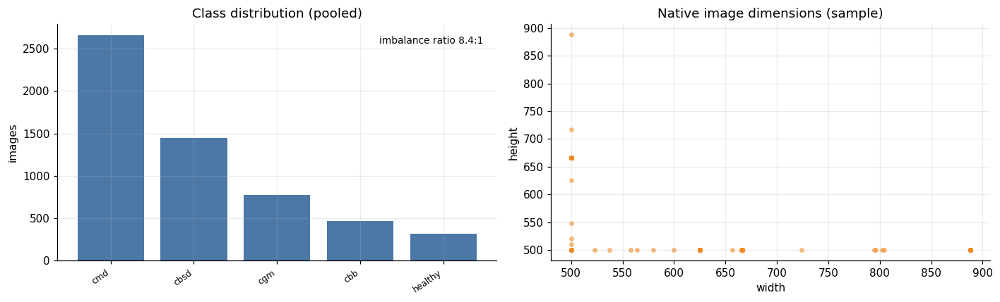

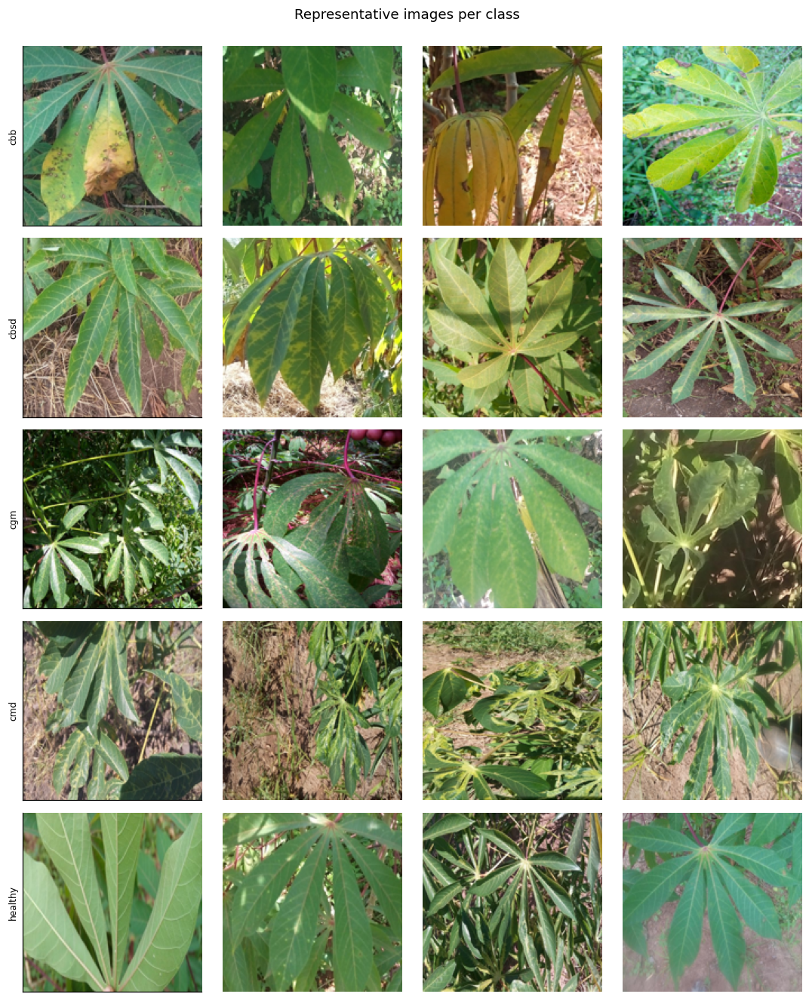

In [5]:
from PIL import Image

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
vc = data.label_name.value_counts()
axes[0].bar(range(len(vc)), vc.values, color="#4C78A8")
axes[0].set_xticks(range(len(vc)))
axes[0].set_xticklabels(vc.index, rotation=35, ha="right", fontsize=8)
axes[0].set_title("Class distribution (pooled)")
axes[0].set_ylabel("images")
imb = vc.max() / vc.min()
axes[0].text(0.97, 0.95, "imbalance ratio %.1f:1" % imb, transform=axes[0].transAxes,
             ha="right", va="top", fontsize=9)

sizes = []
for p in data.path.sample(min(120, len(data)), random_state=0):
    try:
        with Image.open(p) as im:
            sizes.append(im.size)
    except Exception:
        pass
sizes = np.array(sizes)
axes[1].scatter(sizes[:, 0], sizes[:, 1], s=12, alpha=0.5, color="#F58518")
axes[1].set_xlabel("width"); axes[1].set_ylabel("height")
axes[1].set_title("Native image dimensions (sample)")
plt.tight_layout(); plt.show()

# A grid of examples, one row per class.
n_show = min(5, len(CLASSES))
fig, axes = plt.subplots(n_show, 4, figsize=(10, 2.4 * n_show))
axes = np.atleast_2d(axes)
for r, cname in enumerate(CLASSES[:n_show]):
    sub = data[data.label_name == cname].sample(4, random_state=1)
    for c, (_, row) in enumerate(sub.iterrows()):
        axes[r, c].imshow(Image.open(row.path).convert("RGB").resize((160, 160)))
        axes[r, c].axis("off")
    axes[r, 0].set_ylabel(cname, fontsize=8)
    axes[r, 0].axis("on"); axes[r, 0].set_xticks([]); axes[r, 0].set_yticks([])
plt.suptitle("Representative images per class", y=1.0)
plt.tight_layout(); plt.show()

## 4. Farm partition

A stratified 20% test set is held out first, and no farm ever sees it. The rest is split
into 10 farms with a Dirichlet(α) prior over each farm's class mix (Hsu et al., 2019). A
large α gives every farm roughly the same mix; a small α gives farms that mostly see one or
two diseases. The main run uses α = 0.4. Each farm keeps 10% of its own data for validation.

In [6]:
from sklearn.model_selection import train_test_split

# Global held-out test set, stratified, never seen by any client.
train_pool, test_df = train_test_split(
    data, test_size=cfg.test_frac, stratify=data.label, random_state=cfg.seed)
train_pool = train_pool.reset_index(drop=True)
test_df = test_df.reset_index(drop=True)

def dirichlet_partition(df, n_clients, alpha, seed=42):
    """Assign row indices to clients with class proportions drawn from Dirichlet(alpha)."""
    rng = np.random.default_rng(seed)
    client_idx = [[] for _ in range(n_clients)]
    for cls in sorted(df.label.unique()):
        idx = df.index[df.label == cls].to_numpy().copy()   # .copy(): pandas returns read-only
        rng.shuffle(idx)
        props = rng.dirichlet(np.repeat(alpha, n_clients))
        cuts = (np.cumsum(props) * len(idx)).astype(int)[:-1]
        for cid, chunk in enumerate(np.split(idx, cuts)):
            client_idx[cid].extend(chunk.tolist())
    # Guarantee no client is empty.
    for cid in range(n_clients):
        if len(client_idx[cid]) < 10:
            donor = max(range(n_clients), key=lambda c: len(client_idx[c]))
            moved = [client_idx[donor].pop() for _ in range(10 - len(client_idx[cid]))]
            client_idx[cid].extend(moved)
    return [np.array(sorted(c)) for c in client_idx]

def safe_split(sub, test_size, seed):
    """Stratify only when every class has >=2 members, else fall back to random.

    At low alpha a farm can legitimately hold a single example of a class, which
    makes a stratified split impossible.
    """
    counts = sub.label.value_counts()
    can_stratify = (len(counts) > 1 and counts.min() >= 2
                    and len(sub) * test_size >= len(counts))
    try:
        return train_test_split(sub, test_size=test_size, random_state=seed,
                                stratify=sub.label if can_stratify else None)
    except ValueError:
        return train_test_split(sub, test_size=test_size, random_state=seed)

client_indices = dirichlet_partition(train_pool, cfg.n_clients, cfg.dirichlet_alpha, cfg.seed)

# Each farm holds out its own local validation split.
client_train, client_val = [], []
for idx in client_indices:
    tr, va = safe_split(train_pool.loc[idx], cfg.val_frac, cfg.seed)
    client_train.append(tr.reset_index(drop=True))
    client_val.append(va.reset_index(drop=True))

print("global test set :", len(test_df))
print("farms           :", cfg.n_clients)
print("alpha           :", cfg.dirichlet_alpha)
print()
for i, (tr, va) in enumerate(zip(client_train, client_val)):
    print("  farm %2d | train %5d | val %4d | classes present %d"
          % (i, len(tr), len(va), tr.label.nunique()))

global test set : 1132
farms           : 10
alpha           : 0.4

  farm  0 | train   535 | val   60 | classes present 4
  farm  1 | train    57 | val    7 | classes present 3
  farm  2 | train   178 | val   20 | classes present 5
  farm  3 | train   154 | val   18 | classes present 4
  farm  4 | train   342 | val   39 | classes present 5
  farm  5 | train   305 | val   34 | classes present 5
  farm  6 | train   283 | val   32 | classes present 3
  farm  7 | train   483 | val   54 | classes present 5
  farm  8 | train  1020 | val  114 | classes present 4
  farm  9 | train   710 | val   79 | classes present 5


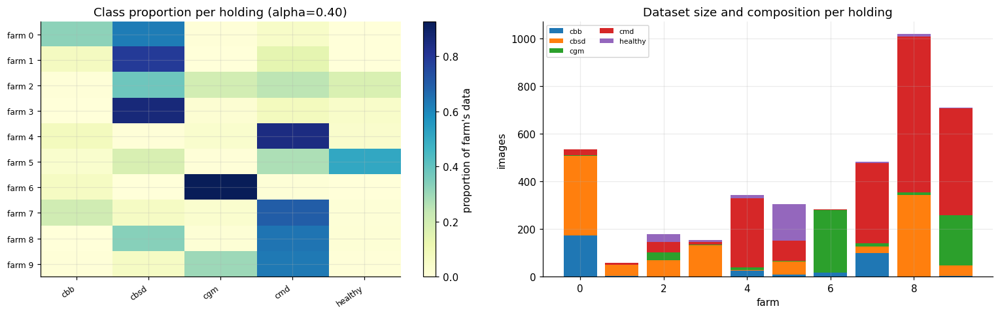

Mean across-farm std of class proportions: 0.226  (0 = perfectly IID)


In [7]:
# How the disease mix differs between farms.
mat = np.zeros((cfg.n_clients, len(CLASSES)))
for i, tr in enumerate(client_train):
    counts = tr.label.value_counts()
    for cls, n in counts.items():
        mat[i, cls] = n
row_prop = mat / np.clip(mat.sum(1, keepdims=True), 1, None)

fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
im = axes[0].imshow(row_prop, aspect="auto", cmap="YlGnBu", vmin=0, vmax=row_prop.max())
axes[0].set_xticks(range(len(CLASSES)))
axes[0].set_xticklabels(CLASSES, rotation=35, ha="right", fontsize=8)
axes[0].set_yticks(range(cfg.n_clients))
axes[0].set_yticklabels(["farm %d" % i for i in range(cfg.n_clients)], fontsize=8)
axes[0].set_title("Class proportion per holding (alpha=%.2f)" % cfg.dirichlet_alpha)
plt.colorbar(im, ax=axes[0], label="proportion of farm's data")

bottom = np.zeros(cfg.n_clients)
for c in range(len(CLASSES)):
    axes[1].bar(range(cfg.n_clients), mat[:, c], bottom=bottom, label=CLASSES[c])
    bottom += mat[:, c]
axes[1].set_xlabel("farm"); axes[1].set_ylabel("images")
axes[1].set_title("Dataset size and composition per holding")
axes[1].legend(fontsize=7, ncol=2)
plt.tight_layout(); plt.show()

skew = row_prop.std(axis=0).mean()
print("Mean across-farm std of class proportions: %.3f  (0 = perfectly IID)" % skew)

## 5. Model

ResNet-18 pretrained on ImageNet, with dropout before the final layer.

BatchNorm is a problem in federated training. Each farm computes running statistics on its
own data, and averaging statistics from farms with different disease mixes does not give
meaningful values (Hsieh et al., 2020). Replacing it with GroupNorm avoids that, but throws
away the pretrained normalisation layers, and in early tests here that version barely
trained. Instead, BatchNorm keeps its ImageNet statistics, frozen. Nothing farm-specific is
computed or averaged, and the scale and shift parameters still train as usual.

Farms train with plain SGD. A farm starts its optimiser afresh every round and takes only a
few steps. With Adam, those first steps move every weight by about the learning rate
whatever its gradient, which drowned out the signal from small farms.

The dropout layer is also used at test time in §8 to estimate uncertainty.

In [8]:
import torchvision.transforms as T
from torchvision import models

MEAN, STD = [0.485, 0.456, 0.406], [0.229, 0.224, 0.225]

train_tf = T.Compose([
    T.RandomResizedCrop(cfg.img_size, scale=(0.65, 1.0)),
    T.RandomHorizontalFlip(),
    T.RandomVerticalFlip(),
    T.ColorJitter(0.25, 0.25, 0.25, 0.05),
    T.ToTensor(),
    T.Normalize(MEAN, STD),
    T.RandomErasing(p=0.2, scale=(0.02, 0.12)),
])

eval_tf = T.Compose([
    T.Resize(int(cfg.img_size * 1.14)),
    T.CenterCrop(cfg.img_size),
    T.ToTensor(),
    T.Normalize(MEAN, STD),
])

class LeafDataset(Dataset):
    def __init__(self, df, tf):
        self.paths = df.path.tolist()
        self.labels = df.label.tolist()
        self.tf = tf
    def __len__(self):
        return len(self.paths)
    def __getitem__(self, i):
        img = Image.open(self.paths[i]).convert("RGB")
        return self.tf(img), self.labels[i]

def loader(df, tf, shuffle, bs=None):
    return DataLoader(LeafDataset(df, tf), batch_size=bs or cfg.batch_size,
                      shuffle=shuffle, num_workers=cfg.num_workers,
                      pin_memory=(DEVICE.type == "cuda"), drop_last=False,
                      persistent_workers=cfg.num_workers > 0)

test_loader = loader(test_df, eval_tf, False)
print("test batches:", len(test_loader))

test batches: 36


In [9]:
def bn_to_gn(module, groups=8):
    """Recursively replace BatchNorm2d with GroupNorm, carrying over the affine parameters."""
    for name, child in module.named_children():
        if isinstance(child, nn.BatchNorm2d):
            c = child.num_features
            g = groups
            while c % g != 0 and g > 1:
                g -= 1
            gn = nn.GroupNorm(g, c)
            if child.affine:
                gn.weight.data.copy_(child.weight.data)
                gn.bias.data.copy_(child.bias.data)
            setattr(module, name, gn)
        else:
            bn_to_gn(child, groups)
    return module

def set_bn_eval(model):
    """Under cfg.norm == "frozen_bn", keep BatchNorm running statistics fixed during training."""
    if cfg.norm == "frozen_bn":
        for m in model.modules():
            if isinstance(m, nn.modules.batchnorm._BatchNorm):
                m.eval()
    return model

def build_model(arch=None, n_classes=None, pretrained=True, norm=None):
    arch = arch or cfg.arch
    n_classes = n_classes or len(CLASSES)
    norm = norm or cfg.norm
    if arch == "resnet18":
        m = models.resnet18(weights="IMAGENET1K_V1" if pretrained else None)
        m.fc = nn.Sequential(nn.Dropout(cfg.dropout), nn.Linear(m.fc.in_features, n_classes))
    elif arch == "efficientnet_b0":
        m = models.efficientnet_b0(weights="IMAGENET1K_V1" if pretrained else None)
        in_f = m.classifier[-1].in_features
        m.classifier = nn.Sequential(nn.Dropout(cfg.dropout), nn.Linear(in_f, n_classes))
    elif arch == "mobilenet_v3_small":
        m = models.mobilenet_v3_small(weights="IMAGENET1K_V1" if pretrained else None)
        in_f = m.classifier[-1].in_features
        m.classifier[-1] = nn.Linear(in_f, n_classes)
    else:
        raise ValueError("unknown arch: %s" % arch)
    if norm == "groupnorm":
        m = bn_to_gn(m)
    return m

_m = build_model()
n_params = sum(p.numel() for p in _m.parameters())
print("arch      :", cfg.arch)
print("params    : %.2f M" % (n_params / 1e6))
print("normalise :", cfg.norm)
del _m

Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:00<00:00, 243MB/s]


arch      : resnet18
params    : 11.18 M
normalise : frozen_bn


## 6. Training and evaluation functions

In [10]:
from torch.amp import autocast, GradScaler
from sklearn.metrics import f1_score, confusion_matrix, classification_report

criterion = nn.CrossEntropyLoss(label_smoothing=cfg.label_smoothing)

def train_epochs(model, dl, epochs, lr=None, global_params=None, mu=0.0,
                 verbose=False, desc=None, momentum=None):
    """Local training. If global_params is given with mu>0, applies the FedProx term."""
    model.to(DEVICE).train()
    set_bn_eval(model)
    if cfg.optimizer == "sgd":
        opt = torch.optim.SGD(model.parameters(), lr=lr or cfg.lr, momentum=cfg.momentum if momentum is None else momentum,
                              weight_decay=cfg.weight_decay)
    else:
        opt = torch.optim.AdamW(model.parameters(), lr=lr or cfg.lr,
                                weight_decay=cfg.weight_decay)
    scaler = GradScaler(DEVICE.type, enabled=cfg.use_amp)
    hist = []
    for ep in range(epochs):
        tot, correct, loss_sum = 0, 0, 0.0
        bar = tqdm(dl, leave=False, disable=desc is None,
                   desc="%s ep%d/%d" % (desc or "", ep + 1, epochs))
        for x, y in bar:
            x, y = x.to(DEVICE, non_blocking=True), y.to(DEVICE, non_blocking=True)
            opt.zero_grad(set_to_none=True)
            with autocast(DEVICE.type, enabled=cfg.use_amp):
                out = model(x)
                loss = criterion(out, y)
            if global_params is not None and mu > 0:
                prox = sum(((p - g.to(DEVICE)) ** 2).sum()
                           for p, g in zip(model.parameters(), global_params))
                loss = loss + (mu / 2.0) * prox
            if not torch.isfinite(loss):
                raise FloatingPointError(
                    "Training loss is not finite. Lower cfg.lr (currently %g) and rerun." % (lr or cfg.lr))
            scaler.scale(loss).backward()
            scaler.unscale_(opt)
            torch.nn.utils.clip_grad_norm_(model.parameters(), cfg.grad_clip)
            scaler.step(opt); scaler.update()
            loss_sum += loss.item() * y.size(0)
            correct += (out.argmax(1) == y).sum().item()
            tot += y.size(0)
            if desc is not None:
                bar.set_postfix(loss="%.3f" % (loss_sum / tot), acc="%.3f" % (correct / tot))
        hist.append({"loss": loss_sum / tot, "acc": correct / tot})
        if verbose:
            print("    epoch %d  loss %.4f  acc %.4f" % (ep + 1, hist[-1]["loss"], hist[-1]["acc"]))
    return hist

@torch.no_grad()
def evaluate(model, dl, return_logits=False):
    model.to(DEVICE).eval()
    logits_all, y_all = [], []
    for x, y in dl:
        x = x.to(DEVICE, non_blocking=True)
        with autocast(DEVICE.type, enabled=cfg.use_amp):
            out = model(x)
        logits_all.append(out.float().cpu()); y_all.append(y)
    logits = torch.cat(logits_all); y = torch.cat(y_all)
    pred = logits.argmax(1)
    res = {
        "acc": (pred == y).float().mean().item(),
        "macro_f1": f1_score(y.numpy(), pred.numpy(), average="macro", zero_division=0),
    }
    if return_logits:
        res["logits"], res["y"] = logits, y
    return res

print("primitives ready")

primitives ready


## 7a. Centralised baseline

The same model trained on all the farms' data pooled together. This is what federated
training is trying to match, so federated results are reported as a gap to it.

In [11]:
set_seed(cfg.seed)
central_train = pd.concat(client_train).reset_index(drop=True)
central_val = pd.concat(client_val).reset_index(drop=True)

central_model = build_model()
t0 = time.time()
central_hist = train_epochs(central_model, loader(central_train, train_tf, True),
                            cfg.central_epochs, verbose=True, desc="centralised")
central_time = time.time() - t0

central_res = evaluate(central_model, test_loader, return_logits=True)
print("\nCENTRALISED BASELINE")
print("  test accuracy : %.4f" % central_res["acc"])
print("  macro F1      : %.4f" % central_res["macro_f1"])
print("  wall clock    : %.1f min" % (central_time / 60))

centralised ep1/8:   0%|          | 0/128 [00:00<?, ?it/s]

    epoch 1  loss 1.1545  acc 0.5847


centralised ep2/8:   0%|          | 0/128 [00:00<?, ?it/s]

    epoch 2  loss 0.9651  acc 0.6799


centralised ep3/8:   0%|          | 0/128 [00:00<?, ?it/s]

    epoch 3  loss 0.8648  acc 0.7251


... (6 outputs left out)

centralised ep7/8:   0%|          | 0/128 [00:00<?, ?it/s]

    epoch 7  loss 0.7102  acc 0.7890


centralised ep8/8:   0%|          | 0/128 [00:00<?, ?it/s]

    epoch 8  loss 0.7050  acc 0.8021

CENTRALISED BASELINE
  test accuracy : 0.8224
  macro F1      : 0.7593
  wall clock    : 3.4 min


## 7b. Federated training

Each round, the server sends the current model to every farm, each farm trains for one
epoch on its own data, and the server averages the returned weights, weighted by farm size
(FedAvg, McMahan et al., 2017).

Momentum is kept on the server rather than on the farms (FedAvgM, Hsu et al., 2019). A farm
restarts its optimiser every round and takes only a handful of steps, so momentum on the
farm never builds up. With the same momentum held on the server across rounds, federated
and centralised training have the same effective learning rate, and the gap between them
reflects the farms' differing data rather than a mismatch in optimisation.

Test accuracy is printed every round to follow progress. The reported model is simply the
last round, so the test set plays no part in choosing it.

In [12]:
import hashlib

def get_flat_state(model):
    return {k: v.detach().cpu().clone() for k, v in model.state_dict().items()}

def aggregate(states, weights):
    """Weighted FedAvg over state dicts; integer buffers (num_batches_tracked) copied."""
    w = np.array(weights, dtype=np.float64); w = w / w.sum()
    out = {}
    for k in states[0]:
        ref = states[0][k]
        if ref.dtype.is_floating_point:
            acc = torch.zeros_like(ref, dtype=torch.float64)
            for s, wi in zip(states, w):
                acc += s[k].double() * wi
            out[k] = acc.to(ref.dtype)
        else:
            out[k] = ref.clone()
    return out

def update_norm(global_state, state, param_keys):
    return math.sqrt(sum(((state[k].double() - global_state[k].double()) ** 2).sum().item()
                         for k in param_keys))

def clip_and_noise(global_state, client_states, param_keys, clip, noise_mult):
    """Client-level DP (DP-FedAvg): clip each farm's whole update, equal-weight average,
    Gaussian noise on the average. Buffers are not parameters and get no noise."""
    n = len(client_states)
    out = {}
    scales = [min(1.0, clip / (update_norm(global_state, s, param_keys) + 1e-12))
              for s in client_states]
    sigma = noise_mult * clip / n
    for k, ref in global_state.items():
        if k in param_keys:
            acc = torch.zeros_like(ref, dtype=torch.float64)
            for s, sc in zip(client_states, scales):
                acc += (s[k].double() - ref.double()) * sc / n
            acc += torch.normal(0.0, sigma, size=acc.shape, dtype=torch.float64)
            out[k] = (ref.double() + acc).to(ref.dtype)
        elif ref.dtype.is_floating_point:
            out[k] = torch.stack([s[k].double() for s in client_states]).mean(0).to(ref.dtype)
        else:
            out[k] = ref.clone()
    return out, float(np.mean([sc < 1.0 for sc in scales]))

def dp_epsilon(rounds, sample_rate, noise_mult, delta):
    """ε for client-level DP after `rounds` rounds, via the RDP accountant in Opacus."""
    try:
        from opacus.accountants import RDPAccountant
    except ImportError:
        os.system("pip -q install opacus")
        from opacus.accountants import RDPAccountant
    acc = RDPAccountant()
    for _ in range(rounds):
        acc.step(noise_multiplier=noise_mult, sample_rate=sample_rate)
    return acc.get_epsilon(delta=delta)

def run_fingerprint(algorithm, rounds, use_dp):
    """Identifies the settings and data a checkpoint belongs to."""
    keys = ["arch", "norm", "n_clients", "dirichlet_alpha", "local_epochs", "client_frac",
            "batch_size", "optimizer", "lr", "momentum", "grad_clip", "weight_decay", "label_smoothing", "dropout", "fedprox_mu", "server_momentum", "client_momentum",
            "dp_clip_norm", "dp_noise_multiplier", "seed", "smoke_test", "img_size"]
    blob = {k: getattr(cfg, k) for k in keys}
    blob.update(algorithm=algorithm, rounds=rounds, use_dp=use_dp, classes=CLASSES,
                sizes=[len(t) for t in client_train])
    return hashlib.md5(json.dumps(blob, sort_keys=True, default=str).encode()).hexdigest()[:10]

def run_federated(algorithm="fedavg", rounds=None, alpha_label="", tag="main",
                  checkpoint=True, use_dp=None):
    """Federated training, checkpointed after every round."""
    set_seed(cfg.seed)
    rounds = rounds or cfg.rounds
    use_dp = cfg.use_dp if use_dp is None else use_dp
    if use_dp:
        assert cfg.norm != "batchnorm", "DP needs norm='frozen_bn' or 'groupnorm'"
    global_model = build_model()
    param_keys = {k for k, _ in global_model.named_parameters()}
    global_state = get_flat_state(global_model)
    client_loaders = [loader(tr, train_tf, True) for tr in client_train]
    log, start_round = [], 1
    velocity = {k: torch.zeros_like(v, dtype=torch.float64)
                for k, v in global_state.items() if k in param_keys}

    fp = run_fingerprint(algorithm, rounds, use_dp)
    ckpt_path = os.path.join(CKPT_DIR, "fed_%s_%s.pt" % (tag, fp))
    if checkpoint:
        os.makedirs(CKPT_DIR, exist_ok=True)
        if os.path.exists(ckpt_path):
            ck = torch.load(ckpt_path, map_location="cpu", weights_only=False)
            global_state = ck["state"]; log = ck["log"]; start_round = ck["round"] + 1
            velocity = ck.get("velocity", velocity)
            print("Resuming from round %d (%s)." % (ck["round"], os.path.basename(ckpt_path)))

    n_sample = max(1, int(cfg.client_frac * cfg.n_clients))
    rng = np.random.default_rng(cfg.seed)
    t_start = time.time()

    for rnd in range(start_round, rounds + 1):
        t_round = time.time()
        chosen = rng.choice(cfg.n_clients, size=n_sample, replace=False)
        states, sizes = [], []

        global_params = None
        if algorithm == "fedprox":
            tmp = build_model(); tmp.load_state_dict(global_state)
            global_params = [p.detach().clone() for p in tmp.parameters()]
            del tmp

        for cid in chosen:
            local = build_model()
            local.load_state_dict(global_state)
            train_epochs(local, client_loaders[cid], cfg.local_epochs,
                         global_params=global_params,
                         mu=cfg.fedprox_mu if algorithm == "fedprox" else 0.0,
                         desc="r%d farm%d" % (rnd, cid), momentum=cfg.client_momentum)
            states.append(get_flat_state(local))
            sizes.append(len(client_train[cid]))
            del local
            if DEVICE.type == "cuda":
                torch.cuda.empty_cache()

        norms = [update_norm(global_state, s, param_keys) for s in states]
        clipped = None
        if use_dp:
            new_state, clipped = clip_and_noise(global_state, states, param_keys,
                                                cfg.dp_clip_norm, cfg.dp_noise_multiplier)
        else:
            new_state = aggregate(states, sizes)
        # Server momentum: applied to the (already privatised) average update, so it is
        # post-processing and does not change the DP guarantee.
        if cfg.server_momentum > 0:
            for k in param_keys:
                delta = new_state[k].double() - global_state[k].double()
                velocity[k] = cfg.server_momentum * velocity[k] + delta
                new_state[k] = (global_state[k].double() + velocity[k]).to(global_state[k].dtype)
        global_state = new_state

        global_model.load_state_dict(global_state)
        res = evaluate(global_model, test_loader)
        dt = time.time() - t_round
        log.append({"round": rnd, "acc": res["acc"], "macro_f1": res["macro_f1"],
                    "median_update_norm": float(np.median(norms)),
                    "frac_clipped": clipped, "seconds": round(dt, 1)})

        eta = dt * (rounds - rnd) / 60
        print("round %2d/%-2d | acc %.4f | macro F1 %.4f | update norm %.2f | %5.1fs | ETA %4.1f min %s"
              % (rnd, rounds, res["acc"], res["macro_f1"], np.median(norms), dt, eta, alpha_label))

        if checkpoint:
            torch.save({"state": global_state, "velocity": velocity, "log": log, "round": rnd,
                        "config": asdict(cfg)}, ckpt_path)

    global_model.load_state_dict(global_state)
    print("\nTotal federated wall clock: %.1f min" % ((time.time() - t_start) / 60))
    return global_model, pd.DataFrame(log)

fed_model, fed_log = run_federated(cfg.algorithm, use_dp=False)

r1 farm2 ep1/1:   0%|          | 0/6 [00:00<?, ?it/s]

r1 farm9 ep1/1:   0%|          | 0/23 [00:00<?, ?it/s]

r1 farm1 ep1/1:   0%|          | 0/2 [00:00<?, ?it/s]

r1 farm6 ep1/1:   0%|          | 0/9 [00:00<?, ?it/s]

r1 farm3 ep1/1:   0%|          | 0/5 [00:00<?, ?it/s]

r1 farm8 ep1/1:   0%|          | 0/32 [00:00<?, ?it/s]

... (320 outputs left out)

r30 farm2 ep1/1:   0%|          | 0/6 [00:00<?, ?it/s]

r30 farm9 ep1/1:   0%|          | 0/23 [00:00<?, ?it/s]

r30 farm1 ep1/1:   0%|          | 0/2 [00:00<?, ?it/s]

round 30/30 | acc 0.7836 | macro F1 0.6622 | update norm 0.04 |  40.2s | ETA  0.0 min 

Total federated wall clock: 20.3 min


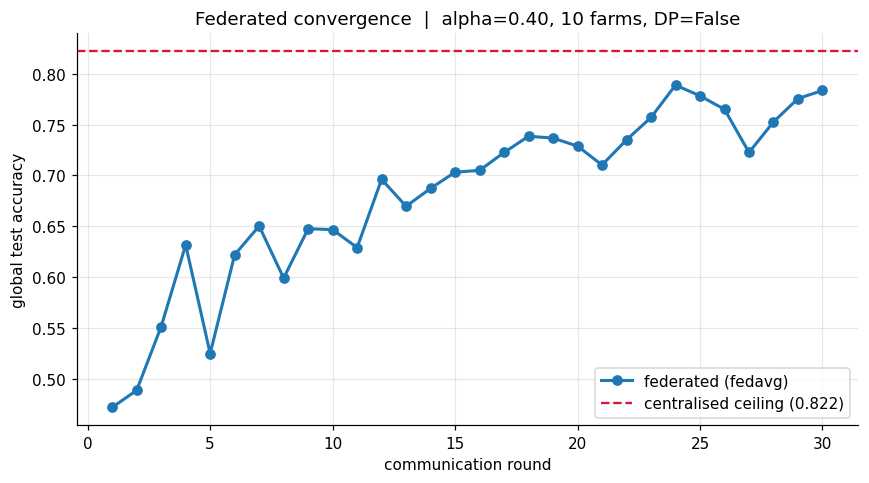

majority-class rate (chance level): 0.4700
centralised : 0.8224  (macro F1 0.7593)
federated   : 0.7836  (macro F1 0.6622)
federation cost: 0.0389 accuracy (4.7% relative)


In [13]:
fed_res = evaluate(fed_model, test_loader, return_logits=True)
gap = central_res["acc"] - fed_res["acc"]

plt.figure(figsize=(8, 4.5))
plt.plot(fed_log["round"], fed_log["acc"], marker="o", lw=2,
         label="federated (%s)" % cfg.algorithm)
plt.axhline(central_res["acc"], ls="--", color="crimson",
            label="centralised ceiling (%.3f)" % central_res["acc"])
plt.xlabel("communication round"); plt.ylabel("global test accuracy")
plt.title("Federated convergence  |  alpha=%.2f, %d farms, DP=%s"
          % (cfg.dirichlet_alpha, cfg.n_clients, False))
plt.legend(); plt.grid(alpha=0.3); plt.tight_layout(); plt.show()

majority = test_df.label.value_counts(normalize=True).max()
print("majority-class rate (chance level): %.4f" % majority)
print("centralised : %.4f  (macro F1 %.4f)" % (central_res["acc"], central_res["macro_f1"]))
print("federated   : %.4f  (macro F1 %.4f)" % (fed_res["acc"], fed_res["macro_f1"]))
print("federation cost: %.4f accuracy (%.1f%% relative)"
      % (gap, 100 * gap / max(central_res["acc"], 1e-9)))

## 7c. Client-level differential privacy (off by default)

With `RUN_DP = True`, federated training is repeated with DP-FedAvg (McMahan et al., 2018) at
each noise level in `DP_NOISE`. Each farm's whole update is clipped to a fixed norm C, the
clipped updates are averaged with equal weight, and Gaussian noise is added to the average.
The equal weighting matters: weighting by farm size would let a large farm's update exceed
the bound the noise is set for. ε comes from the RDP accountant in Opacus. Server momentum is
applied after the noise, so it does not change ε.

This protects whether a given farm took part, not individual images. With only ten farms,
the noise needed for a meaningful ε is large compared with the averaged update, so expect a
steep loss of accuracy. C defaults to the median update norm from the main run; set
`DP_CLIP` to choose it yourself. Each noise level costs about as much as the main run.

In [14]:
RUN_DP = False
DP_NOISE = [0.5, 1.0, 2.0]
DP_CLIP = None            # None = median update norm of the non-private run

dp_df = None
if RUN_DP:
    original_z, original_clip = cfg.dp_noise_multiplier, cfg.dp_clip_norm
    cfg.dp_clip_norm = float(DP_CLIP or fed_log.median_update_norm.median())
    print("clip norm C = %.4f (median update norm of the non-private run). Choosing C from the"
          "\nnon-private run is a hyperparameter choice outside the privacy accounting."
          % cfg.dp_clip_norm)
    rows = []
    n_sample = max(1, int(cfg.client_frac * cfg.n_clients))
    for z in DP_NOISE:
        cfg.dp_noise_multiplier = z
        m, lg = run_federated(cfg.algorithm, tag="dp", use_dp=True)
        r = evaluate(m, test_loader)
        rows.append({"noise_multiplier": z, "clip_norm": cfg.dp_clip_norm,
                     "epsilon": dp_epsilon(len(lg), n_sample / cfg.n_clients, z, cfg.dp_delta),
                     "delta": cfg.dp_delta, "test_acc": r["acc"], "macro_f1": r["macro_f1"],
                     "frac_clipped": lg.frac_clipped.mean()})
        del m
        if DEVICE.type == "cuda":
            torch.cuda.empty_cache()
    cfg.dp_noise_multiplier, cfg.dp_clip_norm = original_z, original_clip
    dp_df = pd.DataFrame(rows)
    print(dp_df.to_string(index=False))
    print("non-private federated: acc %.4f, macro F1 %.4f" % (fed_res["acc"], fed_res["macro_f1"]))
else:
    print("DP runs skipped. Set RUN_DP = True to run them.")

DP runs skipped. Set RUN_DP = True to run them.


## 8. Calibration, uncertainty and per-farm results

Three checks on whether the federated model's output can be acted on: whether its
confidence matches how often it is right, whether it is less certain on the cases it gets
wrong, and how it does for each farm rather than on average.

validation images across farms : 457
temperature                    : 0.871
ECE before                     : 0.0539
ECE after                      : 0.0261
(1132 test images over 15 bins: differences of ~0.01 in ECE are within noise)


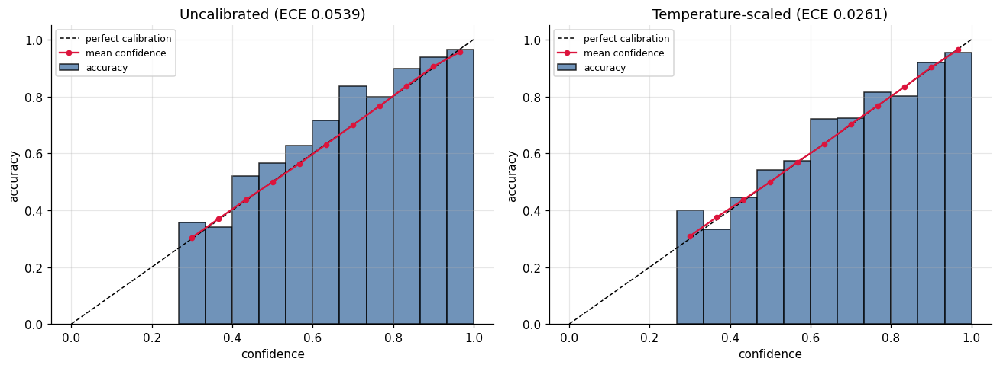

In [15]:
def expected_calibration_error(probs, labels, n_bins=15):
    conf, pred = probs.max(1)
    correct = (pred == labels).float()
    edges = torch.linspace(0, 1, n_bins + 1)
    ece, bins = 0.0, []
    for i in range(n_bins):
        lo, hi = edges[i], edges[i + 1]
        m = (conf > lo) & (conf <= hi)
        if m.sum() > 0:
            acc_b = correct[m].mean().item()
            conf_b = conf[m].mean().item()
            ece += (m.float().mean().item()) * abs(acc_b - conf_b)
            bins.append((0.5 * (lo + hi).item(), acc_b, conf_b, m.sum().item()))
    return ece, bins

# Temperature scaling (Guo et al., 2017) without pooling validation data: each farm
# returns its summed NLL for every candidate temperature, and the server picks the
# temperature with the lowest total.
T_GRID = torch.exp(torch.linspace(math.log(0.25), math.log(4.0), 41))
nll_sum = torch.zeros(len(T_GRID), dtype=torch.float64)
n_val_total = 0
for va in client_val:
    if len(va) == 0:
        continue
    out = evaluate(fed_model, loader(va, eval_tf, False), return_logits=True)
    for j, T in enumerate(T_GRID):
        nll_sum[j] += F.cross_entropy(out["logits"] / T, out["y"], reduction="sum").double()
    n_val_total += len(va)
T_opt = T_GRID[int(nll_sum.argmin())].item()

probs_raw = F.softmax(fed_res["logits"], dim=1)
probs_cal = F.softmax(fed_res["logits"] / T_opt, dim=1)
ece_raw, bins_raw = expected_calibration_error(probs_raw, fed_res["y"])
ece_cal, bins_cal = expected_calibration_error(probs_cal, fed_res["y"])

print("validation images across farms : %d" % n_val_total)
print("temperature                    : %.3f%s" % (T_opt, "  (at grid edge - widen T_GRID)"
      if T_opt in (T_GRID[0].item(), T_GRID[-1].item()) else ""))
print("ECE before                     : %.4f" % ece_raw)
print("ECE after                      : %.4f" % ece_cal)
print("(%d test images over 15 bins: differences of ~0.01 in ECE are within noise)"
      % len(fed_res["y"]))

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
for ax, bins, e, title in [(axes[0], bins_raw, ece_raw, "Uncalibrated"),
                           (axes[1], bins_cal, ece_cal, "Temperature-scaled")]:
    if bins:
        c, a, cf, _ = zip(*bins)
        ax.bar(c, a, width=1 / 15, edgecolor="k", alpha=0.8, label="accuracy", color="#4C78A8")
        ax.plot([0, 1], [0, 1], "k--", lw=1, label="perfect calibration")
        ax.plot(c, cf, "o-", color="crimson", ms=4, label="mean confidence")
    ax.set_xlabel("confidence"); ax.set_ylabel("accuracy")
    ax.set_title("%s (ECE %.4f)" % (title, e)); ax.legend(fontsize=8); ax.grid(alpha=0.3)
plt.tight_layout(); plt.show()

MC-dropout accuracy : 0.7774
mean epistemic unc. | correct 0.0140 | incorrect 0.0216


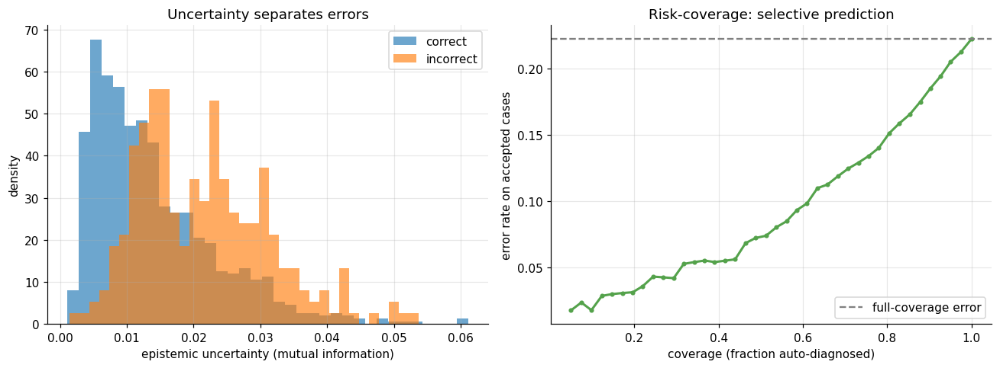

at 49% coverage -> error 0.0725
at 71% coverage -> error 0.1248
at 90% coverage -> error 0.1851


In [16]:
@torch.no_grad()
def mc_dropout_predict(model, dl, n_passes=20):
    """Enable dropout at inference to approximate predictive uncertainty."""
    model.to(DEVICE).eval()
    for m in model.modules():
        if isinstance(m, nn.Dropout):
            m.train()
    all_probs, ys = [], []
    for x, y in dl:
        x = x.to(DEVICE, non_blocking=True)
        passes = []
        for _ in range(n_passes):
            with autocast(DEVICE.type, enabled=cfg.use_amp):
                passes.append(F.softmax(model(x).float(), dim=1).cpu())
        all_probs.append(torch.stack(passes))   # [P, B, C]
        ys.append(y)
    probs = torch.cat(all_probs, dim=1)
    return probs, torch.cat(ys)

mc_probs, mc_y = mc_dropout_predict(fed_model, test_loader, n_passes=15)
mean_probs = mc_probs.mean(0)

# Decompose: total entropy = aleatoric (expected entropy) + epistemic (mutual info)
eps = 1e-12
total_H = -(mean_probs * (mean_probs + eps).log()).sum(1)
aleatoric = -(mc_probs * (mc_probs + eps).log()).sum(2).mean(0)
epistemic = total_H - aleatoric

pred = mean_probs.argmax(1)
correct = (pred == mc_y)
print("MC-dropout accuracy : %.4f" % correct.float().mean().item())
print("mean epistemic unc. | correct %.4f | incorrect %.4f"
      % (epistemic[correct].mean().item(), epistemic[~correct].mean().item()))

# Risk-coverage: error rate when only the most certain cases are answered.
order = torch.argsort(total_H)
cov, risk = [], []
for frac in np.linspace(0.05, 1.0, 40):
    k = max(1, int(frac * len(order)))
    sel = order[:k]
    cov.append(k / len(order))
    risk.append(1 - correct[sel].float().mean().item())

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
axes[0].hist(epistemic[correct].numpy(), bins=35, alpha=0.65, label="correct", density=True)
axes[0].hist(epistemic[~correct].numpy(), bins=35, alpha=0.65, label="incorrect", density=True)
axes[0].set_xlabel("epistemic uncertainty (mutual information)")
axes[0].set_ylabel("density"); axes[0].set_title("Uncertainty separates errors")
axes[0].legend(); axes[0].grid(alpha=0.3)

axes[1].plot(cov, risk, marker=".", lw=2, color="#54A24B")
axes[1].axhline(1 - correct.float().mean().item(), ls="--", color="gray",
                label="full-coverage error")
axes[1].set_xlabel("coverage (fraction auto-diagnosed)")
axes[1].set_ylabel("error rate on accepted cases")
axes[1].set_title("Risk-coverage: selective prediction")
axes[1].legend(); axes[1].grid(alpha=0.3)
plt.tight_layout(); plt.show()

for target in (0.5, 0.7, 0.9):
    i = int(np.argmin(np.abs(np.array(cov) - target)))
    print("at %.0f%% coverage -> error %.4f" % (100 * cov[i], risk[i]))

 farm  n_train  classes  federated_acc  centralised_acc
    0      535        4         0.6880           0.6735
    1       57        3         0.8502           0.7154
    2      178        5         0.7749           0.7755
    3      154        4         0.8736           0.7062
    4      342        5         0.8169           0.9137
    5      305        5         0.6819           0.7636
    6      283        3         0.6171           0.7898
    7      483        5         0.7478           0.8631
    8     1020        4         0.8830           0.8594
    9      710        5         0.8083           0.8901

federated   mean 0.7742 | worst farm 0.6171 | std 0.0893
centralised mean 0.7950 | worst farm 0.6735 | std 0.0832


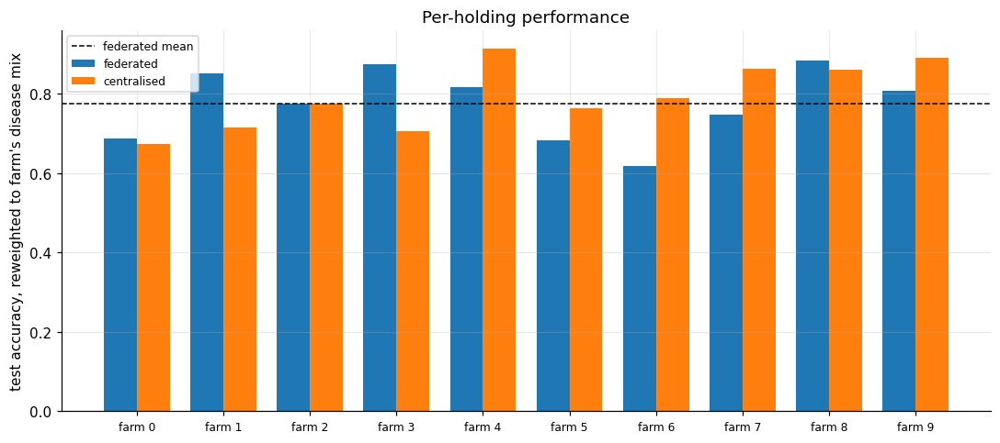

In [17]:
# A farm's own validation split is too small to compare farms, so each farm is scored
# on the test set reweighted to that farm's disease mix.
def farm_weighted_acc(pred, y, farm_train):
    p_farm = farm_train.label.value_counts(normalize=True)
    p_test = pd.Series(y.numpy()).value_counts(normalize=True)
    w = np.array([p_farm.get(c, 0.0) / p_test[c] for c in y.numpy()])
    return float(((pred == y).numpy() * w).sum() / w.sum())

central_pred = central_res["logits"].argmax(1)
fed_pred = fed_res["logits"].argmax(1)
rows = []
for cid, tr in enumerate(client_train):
    rows.append({"farm": cid, "n_train": len(tr), "classes": tr.label.nunique(),
                 "federated_acc": farm_weighted_acc(fed_pred, fed_res["y"], tr),
                 "centralised_acc": farm_weighted_acc(central_pred, central_res["y"], tr)})
farm_df = pd.DataFrame(rows)
print(farm_df.round(4).to_string(index=False))
print()
for col, name in [("federated_acc", "federated  "), ("centralised_acc", "centralised")]:
    print("%s mean %.4f | worst farm %.4f | std %.4f"
          % (name, farm_df[col].mean(), farm_df[col].min(), farm_df[col].std()))

x = np.arange(len(farm_df)); w = 0.38
plt.figure(figsize=(10, 4.5))
plt.bar(x - w/2, farm_df.federated_acc, w, label="federated")
plt.bar(x + w/2, farm_df.centralised_acc, w, label="centralised")
plt.axhline(farm_df.federated_acc.mean(), ls="--", color="k", lw=1, label="federated mean")
plt.xticks(x, ["farm %d" % i for i in x], fontsize=8)
plt.ylabel("test accuracy, reweighted to farm's disease mix")
plt.title("Per-holding performance")
plt.legend(fontsize=8); plt.grid(alpha=0.3, axis="y"); plt.tight_layout(); plt.show()

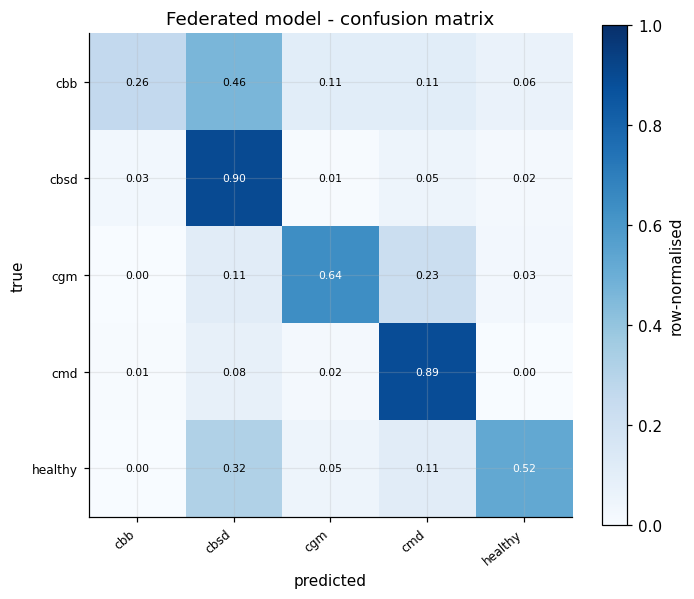

              precision    recall  f1-score   support

         cbb       0.67      0.26      0.37        93
        cbsd       0.68      0.90      0.77       289
         cgm       0.79      0.64      0.70       155
         cmd       0.88      0.89      0.88       532
     healthy       0.65      0.52      0.58        63

    accuracy                           0.78      1132
   macro avg       0.73      0.64      0.66      1132
weighted avg       0.78      0.78      0.77      1132



In [18]:
cm = confusion_matrix(fed_res["y"].numpy(), fed_res["logits"].argmax(1).numpy())
cmn = cm / np.clip(cm.sum(1, keepdims=True), 1, None)

plt.figure(figsize=(6.5, 5.5))
plt.imshow(cmn, cmap="Blues", vmin=0, vmax=1)
plt.colorbar(label="row-normalised")
plt.xticks(range(len(CLASSES)), CLASSES, rotation=40, ha="right", fontsize=8)
plt.yticks(range(len(CLASSES)), CLASSES, fontsize=8)
for i in range(len(CLASSES)):
    for j in range(len(CLASSES)):
        plt.text(j, i, "%.2f" % cmn[i, j], ha="center", va="center", fontsize=7,
                 color="white" if cmn[i, j] > 0.5 else "black")
plt.xlabel("predicted"); plt.ylabel("true")
plt.title("Federated model - confusion matrix")
plt.tight_layout(); plt.show()

print(classification_report(fed_res["y"].numpy(), fed_res["logits"].argmax(1).numpy(),
                            target_names=CLASSES, zero_division=0))

## 9. Grad-CAM

Grad-CAM shows which parts of an image drove a prediction. The thing to check is whether the
model looks at lesions and leaf tissue, or at the background, the image borders or anything
else that could be a shortcut.

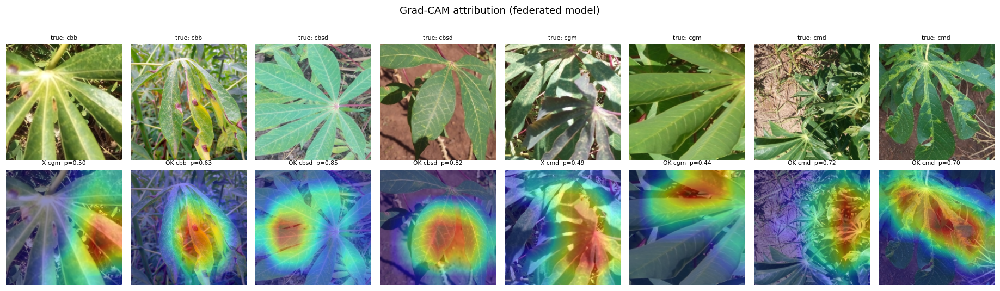

In [19]:
class GradCAM:
    """Minimal Grad-CAM. Hooks the final convolutional layer."""
    def __init__(self, model, target_layer=None):
        self.model = model.to(DEVICE).eval()
        if target_layer is None:
            convs = [m for m in model.modules() if isinstance(m, nn.Conv2d)]
            target_layer = convs[-1]
        self.acts, self.grads = None, None
        target_layer.register_forward_hook(self._fwd)
        target_layer.register_full_backward_hook(self._bwd)
    def _fwd(self, m, i, o):
        self.acts = o.detach()
    def _bwd(self, m, gi, go):
        self.grads = go[0].detach()
    def __call__(self, x, cls=None):
        x = x.to(DEVICE).requires_grad_(True)
        out = self.model(x)
        if cls is None:
            cls = out.argmax(1)
        self.model.zero_grad()
        out.gather(1, cls.view(-1, 1)).sum().backward()
        w = self.grads.mean(dim=(2, 3), keepdim=True)
        cam = F.relu((w * self.acts).sum(1, keepdim=True))
        cam = F.interpolate(cam, size=x.shape[-2:], mode="bilinear", align_corners=False)
        cam = cam.squeeze(1)
        cam = cam - cam.amin(dim=(1, 2), keepdim=True)
        cam = cam / (cam.amax(dim=(1, 2), keepdim=True) + 1e-8)
        return cam.cpu(), out.detach().cpu(), cls.cpu()

def denorm(t):
    img = t.cpu().numpy().transpose(1, 2, 0)
    img = img * np.array(STD) + np.array(MEAN)
    return np.clip(img, 0, 1)

cam_model = copy.deepcopy(fed_model)
gradcam = GradCAM(cam_model)

# Two test images per class.
sample = pd.concat([g.sample(min(2, len(g)), random_state=3)
                    for _, g in test_df.groupby("label")]).reset_index(drop=True)
ds = LeafDataset(sample, eval_tf)
n = min(8, len(ds))

fig, axes = plt.subplots(2, n, figsize=(2.1 * n, 4.8))
axes = np.atleast_2d(axes)
for i in range(n):
    x, y = ds[i]
    cam, logits, pred = gradcam(x.unsqueeze(0))
    p = F.softmax(logits, 1).max().item()
    axes[0, i].imshow(denorm(x)); axes[0, i].axis("off")
    axes[0, i].set_title("true: %s" % CLASSES[y][:14], fontsize=7)
    axes[1, i].imshow(denorm(x))
    axes[1, i].imshow(cam[0], cmap="jet", alpha=0.45)
    axes[1, i].axis("off")
    ok = "OK" if pred.item() == y else "X"
    axes[1, i].set_title("%s %s  p=%.2f" % (ok, CLASSES[pred.item()][:12], p), fontsize=7)
plt.suptitle("Grad-CAM attribution (federated model)", y=1.02)
plt.tight_layout(); plt.show()
del cam_model

## 10. Distillation and quantisation

The federated ResNet-18 is distilled into a MobileNetV3-Small on the server. The student
learns only from the teacher's predictions on unlabelled leaf images, so no farm data is
needed (as in FedDF, Lin et al., 2020). Dynamic INT8 quantisation is then applied. In PyTorch
it covers only the linear layers, so most of the size reduction comes from distillation. All
three models are scored on the same test set, on CPU.

In [20]:
class UnlabelledDataset(Dataset):
    def __init__(self, paths, tf):
        self.paths, self.tf = paths, tf
    def __len__(self):
        return len(self.paths)
    def __getitem__(self, i):
        return self.tf(Image.open(self.paths[i]).convert("RGB")), -1

def kd_train(teacher, student, dl, epochs, Temp=None):
    """Distil on unlabelled images: the only target is the teacher's softened prediction."""
    Temp = cfg.distill_temp if Temp is None else Temp
    teacher.to(DEVICE).eval()
    student.to(DEVICE).train()
    opt = torch.optim.AdamW(student.parameters(), lr=1e-3, weight_decay=cfg.weight_decay)
    scaler = GradScaler(DEVICE.type, enabled=cfg.use_amp)
    for ep in range(epochs):
        tot, loss_sum = 0, 0.0
        for x, _ in dl:
            x = x.to(DEVICE, non_blocking=True)
            opt.zero_grad(set_to_none=True)
            with autocast(DEVICE.type, enabled=cfg.use_amp):
                with torch.no_grad():
                    t_logits = teacher(x)
                s_logits = student(x)
                loss = F.kl_div(F.log_softmax(s_logits.float() / Temp, 1),
                                F.softmax(t_logits.float() / Temp, 1),
                                reduction="batchmean") * (Temp ** 2)
            scaler.scale(loss).backward()
            scaler.step(opt); scaler.update()
            loss_sum += loss.item() * x.size(0); tot += x.size(0)
        print("  distill epoch %d  KL loss %.4f" % (ep + 1, loss_sum / tot))
    return student

transfer = list(unlabelled_paths)
random.Random(cfg.seed).shuffle(transfer)
transfer = transfer[:cfg.smoke_images if cfg.smoke_test else cfg.distill_max_images]
assert transfer, "No unlabelled images found for distillation."
print("server-side transfer set: %d unlabelled images" % len(transfer))

set_seed(cfg.seed)
student = build_model(arch="mobilenet_v3_small", norm="batchnorm")
transfer_dl = DataLoader(UnlabelledDataset(transfer, train_tf), batch_size=cfg.batch_size,
                         shuffle=True, num_workers=cfg.num_workers,
                         pin_memory=(DEVICE.type == "cuda"))
student = kd_train(fed_model, student, transfer_dl, cfg.distill_epochs)
student_res = evaluate(student, test_loader)
print("\nstudent test accuracy: %.4f  (macro F1 %.4f)" % (student_res["acc"], student_res["macro_f1"]))

server-side transfer set: 4000 unlabelled images
Downloading: "https://download.pytorch.org/models/mobilenet_v3_small-047dcff4.pth" to /root/.cache/torch/hub/checkpoints/mobilenet_v3_small-047dcff4.pth


100%|██████████| 9.83M/9.83M [00:00<00:00, 183MB/s]


  distill epoch 1  KL loss 0.2431
  distill epoch 2  KL loss 0.1493
  distill epoch 3  KL loss 0.1311
  distill epoch 4  KL loss 0.1274
  distill epoch 5  KL loss 0.1170

student test accuracy: 0.7703  (macro F1 0.6326)


            variant  accuracy  size_MB  cpu_latency_ms
teacher (federated)    0.7836    44.79            14.7
student (distilled)    0.7703     6.21             9.4
     student + INT8    0.7721     4.43             9.2


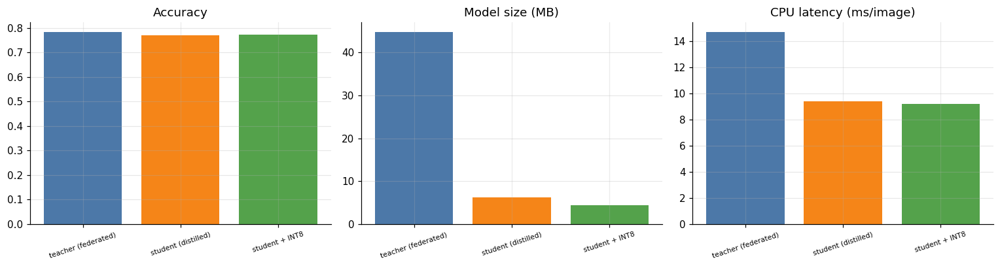

In [21]:
import tempfile

def model_size_mb(model):
    with tempfile.TemporaryDirectory() as d:
        tmp = os.path.join(d, "m.pt")
        torch.save(model.state_dict(), tmp)
        return os.path.getsize(tmp) / 1e6

@torch.no_grad()
def cpu_latency_ms(model, n=30, warmup=5):
    model = model.to("cpu").eval()
    x = torch.randn(1, 3, cfg.img_size, cfg.img_size)
    for _ in range(warmup):
        model(x)
    t0 = time.perf_counter()
    for _ in range(n):
        model(x)
    return (time.perf_counter() - t0) / n * 1000

# INT8 dynamic quantisation of the student's linear layers.
student_cpu = copy.deepcopy(student).to("cpu").eval()
q_student = torch.ao.quantization.quantize_dynamic(
    copy.deepcopy(student_cpu), {nn.Linear}, dtype=torch.qint8)

@torch.no_grad()
def eval_cpu(model, dl):
    """Full test set on CPU, so all three variants are scored identically."""
    model = model.to("cpu").eval()
    corr, tot = 0, 0
    for x, y in dl:
        corr += (model(x).argmax(1) == y).sum().item(); tot += y.size(0)
    return corr / max(tot, 1)

teacher_cpu = copy.deepcopy(fed_model).to("cpu").eval()
variants = [
    ("teacher (federated)", teacher_cpu),
    ("student (distilled)", student_cpu),
    ("student + INT8", q_student),
]
rows = []
for name, m in variants:
    rows.append({"variant": name,
                 "accuracy": round(eval_cpu(m, test_loader), 4),
                 "size_MB": round(model_size_mb(m), 2),
                 "cpu_latency_ms": round(cpu_latency_ms(m), 1)})
eff_df = pd.DataFrame(rows)
print(eff_df.to_string(index=False))

fig, axes = plt.subplots(1, 3, figsize=(14, 3.8))
for ax, col, title in zip(axes, ["accuracy", "size_MB", "cpu_latency_ms"],
                          ["Accuracy", "Model size (MB)", "CPU latency (ms/image)"]):
    ax.bar(eff_df.variant, eff_df[col], color=["#4C78A8", "#F58518", "#54A24B"])
    ax.set_title(title); ax.tick_params(axis="x", rotation=18, labelsize=7)
    ax.grid(alpha=0.3, axis="y")
plt.tight_layout(); plt.show()

del teacher_cpu

## 11. Heterogeneity sweep

The farms are re-partitioned at α = 10, 1 and 0.1 and federated training is rerun for the
same number of rounds as the main run, which supplies the α = 0.4 point. If the gap to the
centralised model mostly closes at α = 10, where farms see nearly the same mix, then the gap
at lower α is the cost of heterogeneity. If a large gap remains even there, something else
is causing it. Final-round results are reported, not the best round, for the same reason as
in §7b.

r1 farm2 ep1/1:   0%|          | 0/13 [00:00<?, ?it/s]

r1 farm9 ep1/1:   0%|          | 0/19 [00:00<?, ?it/s]

r1 farm1 ep1/1:   0%|          | 0/11 [00:00<?, ?it/s]

r1 farm6 ep1/1:   0%|          | 0/12 [00:00<?, ?it/s]

r1 farm3 ep1/1:   0%|          | 0/13 [00:00<?, ?it/s]

r1 farm8 ep1/1:   0%|          | 0/15 [00:00<?, ?it/s]

... (980 outputs left out)

r30 farm2 ep1/1:   0%|          | 0/1 [00:00<?, ?it/s]

r30 farm9 ep1/1:   0%|          | 0/34 [00:00<?, ?it/s]

r30 farm1 ep1/1:   0%|          | 0/1 [00:00<?, ?it/s]

round 30/30 | acc 0.6360 | macro F1 0.2964 | update norm 0.04 |  39.3s | ETA  0.0 min [alpha=0.10]

Total federated wall clock: 20.0 min
 alpha  final_acc  final_macro_f1  gap_macro_f1
  10.0     0.7915          0.6854        0.0739
   1.0     0.7942          0.6601        0.0992
   0.4     0.7836          0.6622        0.0971
   0.1     0.6360          0.2964        0.4629
centralised macro F1: 0.7593


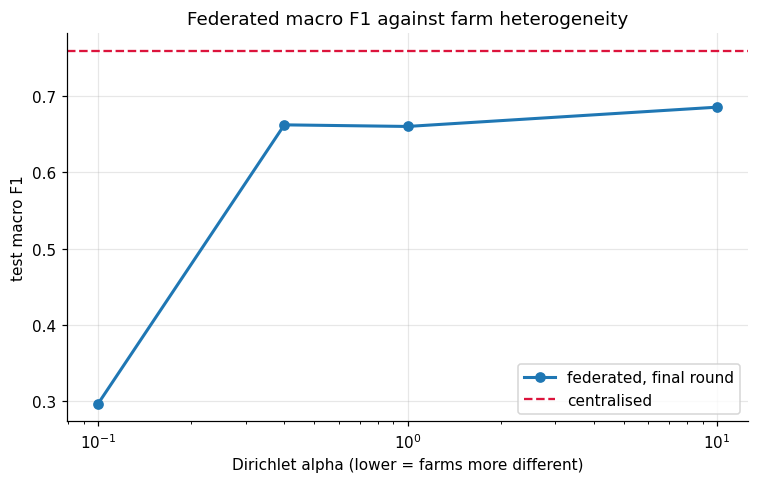

In [22]:
RUN_SWEEP = True
SWEEP_ALPHAS = [10.0, 1.0, 0.1]
SWEEP_ROUNDS = cfg.rounds
sw = None

if RUN_SWEEP:
    # The main run is the alpha = 0.4 point.
    sweep = [{"alpha": cfg.dirichlet_alpha, "final_acc": fed_log.acc.iloc[-1],
              "final_macro_f1": fed_log.macro_f1.iloc[-1]}]
    original_alpha = cfg.dirichlet_alpha
    original_ct, original_cv = client_train, client_val
    for a in SWEEP_ALPHAS:
        cfg.dirichlet_alpha = a
        idxs = dirichlet_partition(train_pool, cfg.n_clients, a, cfg.seed)
        client_train, client_val = [], []
        for idx in idxs:
            tr, va = safe_split(train_pool.loc[idx], cfg.val_frac, cfg.seed)
            client_train.append(tr.reset_index(drop=True))
            client_val.append(va.reset_index(drop=True))
        m, lg = run_federated(cfg.algorithm, rounds=SWEEP_ROUNDS,
                              alpha_label="[alpha=%.2f]" % a, tag="sweep", use_dp=False)
        sweep.append({"alpha": a, "final_acc": lg.acc.iloc[-1],
                      "final_macro_f1": lg.macro_f1.iloc[-1]})
        del m
        if DEVICE.type == "cuda":
            torch.cuda.empty_cache()
    cfg.dirichlet_alpha = original_alpha
    client_train, client_val = original_ct, original_cv

    sw = pd.DataFrame(sweep).sort_values("alpha", ascending=False).reset_index(drop=True)
    sw["gap_macro_f1"] = central_res["macro_f1"] - sw.final_macro_f1
    print(sw.round(4).to_string(index=False))
    print("centralised macro F1: %.4f" % central_res["macro_f1"])

    plt.figure(figsize=(7, 4.5))
    plt.plot(sw.alpha, sw.final_macro_f1, marker="o", lw=2, label="federated, final round")
    plt.axhline(central_res["macro_f1"], ls="--", color="crimson", label="centralised")
    plt.xscale("log"); plt.xlabel("Dirichlet alpha (lower = farms more different)")
    plt.ylabel("test macro F1")
    plt.title("Federated macro F1 against farm heterogeneity")
    plt.legend(); plt.grid(alpha=0.3); plt.tight_layout(); plt.show()
else:
    print("Sweep skipped.")

## 12. Results and export

In [23]:
summary = {
    "smoke_test": bool(cfg.smoke_test),
    "note": ("SMOKE TEST: pipeline check on a subsample, not results"
             if cfg.smoke_test else "full run"),
    "configuration": asdict(cfg),
    "dataset": {
        "n_images": int(len(data)),
        "n_classes": int(len(CLASSES)),
        "classes": CLASSES,
        "n_labelled_full": int(full_counts.sum()),
        "class_counts_full": {k: int(v) for k, v in full_counts.items()},
        "imbalance_ratio_full": float(full_counts.max() / full_counts.min()),
        "majority_class_rate_test": float(test_df.label.value_counts(normalize=True).max()),
    },
    "centralised": {
        "test_acc": float(central_res["acc"]),
        "macro_f1": float(central_res["macro_f1"]),
    },
    "federated": {
        "algorithm": cfg.algorithm,
        "test_acc": float(fed_res["acc"]),
        "macro_f1": float(fed_res["macro_f1"]),
        "federation_cost_abs": float(central_res["acc"] - fed_res["acc"]),
        "worst_farm_acc": float(farm_df.federated_acc.min()),
        "farm_acc_std": float(farm_df.federated_acc.std()),
        "worst_farm_measure": "test accuracy reweighted to the farm's disease mix",
    },
    "differential_privacy": (dp_df.to_dict(orient="records") if dp_df is not None else None),
    "heterogeneity_sweep": (sw.to_dict(orient="records") if sw is not None else None),
    "calibration": {
        "ece_uncalibrated": float(ece_raw),
        "ece_calibrated": float(ece_cal),
        "temperature": float(T_opt),
        "method": "federated grid search on per-farm validation NLL",
    },
    "efficiency": eff_df.to_dict(orient="records"),
    "distillation_transfer_images": len(transfer),
}

out_dir = Path("/content/artifacts"); out_dir.mkdir(exist_ok=True)
(out_dir / "summary.json").write_text(json.dumps(summary, indent=2))
fed_log.to_csv(out_dir / "federated_log.csv", index=False)
farm_df.to_csv(out_dir / "per_farm_results.csv", index=False)
eff_df.to_csv(out_dir / "efficiency.csv", index=False)
torch.save(fed_model.state_dict(), out_dir / "federated_model.pt")
torch.save(student.state_dict(), out_dir / "student_model.pt")

print(json.dumps({k: v for k, v in summary.items() if k != "configuration"}, indent=2))
if cfg.smoke_test:
    print("\n*** SMOKE TEST - these numbers are a pipeline check, not results ***")
print("\nArtefacts written to", out_dir)
for f in sorted(out_dir.iterdir()):
    print("  %-26s %7.2f MB" % (f.name, f.stat().st_size / 1e6))

# Copy to Drive so the results outlive the runtime.
drive_out = Path(RESULTS_DIR)
drive_out.mkdir(parents=True, exist_ok=True)
for f in out_dir.iterdir():
    shutil.copy(f, drive_out / f.name)
print("\nCopied to", drive_out)

{
  "smoke_test": false,
  "note": "full run",
  "dataset": {
    "n_images": 5656,
    "n_classes": 5,
    "classes": [
      "cbb",
      "cbsd",
      "cgm",
      "cmd",
      "healthy"
    ],
    "n_labelled_full": 5656,
    "class_counts_full": {
      "cmd": 2658,
      "cbsd": 1443,
      "cgm": 773,
      "cbb": 466,
      "healthy": 316
    },
    "imbalance_ratio_full": 8.41139240506329,
    "majority_class_rate_test": 0.46996466431095407
  },
  "centralised": {
    "test_acc": 0.8224381804466248,
    "macro_f1": 0.7592962235573415
  },
  "federated": {
    "algorithm": "fedavg",
    "test_acc": 0.7835689187049866,
    "macro_f1": 0.6622088090417708,
    "federation_cost_abs": 0.038869261741638184,
    "worst_farm_acc": 0.6171333954400421,
    "farm_acc_std": 0.08931592742933474,
    "worst_farm_measure": "test accuracy reweighted to the farm's disease mix"
  },
  "differential_privacy": null,
  "heterogeneity_sweep": [
    {
      "alpha": 10.0,
      "final_acc": 0.7915194

In [24]:
# Headline results.
if cfg.smoke_test:
    print("*** SMOKE TEST - not results ***\n")
headline = pd.DataFrame([
    {"setting": "Majority class (chance level)",
     "test_acc": test_df.label.value_counts(normalize=True).max(), "macro_f1": float("nan"),
     "privacy": "-"},
    {"setting": "Centralised (data pooled)", "test_acc": central_res["acc"],
     "macro_f1": central_res["macro_f1"], "privacy": "none"},
    {"setting": "Federated %s%s (alpha=%.2f, %d farms)" % (cfg.algorithm, " + server momentum" if cfg.server_momentum > 0 else "", cfg.dirichlet_alpha, cfg.n_clients),
     "test_acc": fed_res["acc"], "macro_f1": fed_res["macro_f1"],
     "privacy": "images stay on farm"},
])
headline["test_acc"] = headline.test_acc.round(4)
headline["macro_f1"] = headline.macro_f1.round(4)
print(headline.to_string(index=False))
print()
print("Worst-farm accuracy (federated): %.4f" % farm_df.federated_acc.min())
print("ECE after calibration          : %.4f" % ece_cal)
print("Edge model                     : %.2f MB, %.1f ms/image on CPU, accuracy %.4f"
      % (eff_df.size_MB.iloc[-1], eff_df.cpu_latency_ms.iloc[-1], eff_df.accuracy.iloc[-1]))
if dp_df is not None:
    print("\nClient-level DP:")
    print(dp_df.round(4).to_string(index=False))

                                                  setting  test_acc  macro_f1             privacy
                            Majority class (chance level)    0.4700       NaN                   -
                                Centralised (data pooled)    0.8224    0.7593                none
Federated fedavg + server momentum (alpha=0.40, 10 farms)    0.7836    0.6622 images stay on farm

Worst-farm accuracy (federated): 0.6171
ECE after calibration          : 0.0261
Edge model                     : 4.43 MB, 9.2 ms/image on CPU, accuracy 0.7721


## 13. Limitations and next steps

The farms are simulated. They are slices of one centrally held dataset, so the study says
nothing about unreliable connectivity, farms joining and leaving, or differences in cameras
and lighting between farms. The partition varies only each farm's mix of diseases, and in
practice differences in how the images are taken may matter more.

All results come from a single seed and a single partition, so differences of a few points
between settings should not be over-read.

Client-level differential privacy with ten farms buys little privacy at a useful accuracy.
§7c measures the size of that trade-off; it is not a working private system.

The images are RGB leaf photographs only, with no hyperspectral data and no structured data
such as weather, soil or yield.

Next steps, roughly in order: fuse structured farm data with the images while keeping both
on the farm; partition by how images were taken as well as by label; repeat with several
seeds and report intervals; add secure aggregation so the server sees only the sum of the
updates; and test whether a farm's contribution can be removed from the model when it
leaves, and how that removal could be verified.

References: McMahan et al. (2017), Communication-Efficient Learning of Deep Networks from
Decentralized Data · McMahan et al. (2018), Learning Differentially Private Recurrent
Language Models · Hsu et al. (2019), Measuring the Effects of Non-Identical Data Distribution
for Federated Visual Classification · Li et al. (2020), Federated Optimization in
Heterogeneous Networks · Lin et al. (2020), Ensemble Distillation for Robust Model Fusion in
Federated Learning · Hsieh et al. (2020), The Non-IID Data Quagmire of Decentralized Machine
Learning · Guo et al. (2017), On Calibration of Modern Neural Networks · Gal and Ghahramani
(2016), Dropout as a Bayesian Approximation · Selvaraju et al. (2017), Grad-CAM ·
Mironov (2017), Rényi Differential Privacy